# 🐍 Python Foundations for AI
## Class 10 — Final Project: AI Support Desk

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos**

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
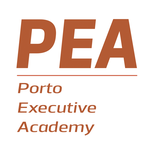
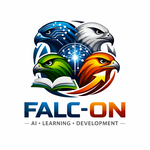
</div>

---

---

# 🏁 Final Project — Project Brief

**Theme:** *from script to product.* Real AI systems are not a chat box: they **take in data, call an AI model, store the results, measure how good they are, and explain what they found.** That is what you build.

---
## 1. What You Will Build — the "AI Support Desk" 🎧🤖

A program that helps a support team with its tickets:

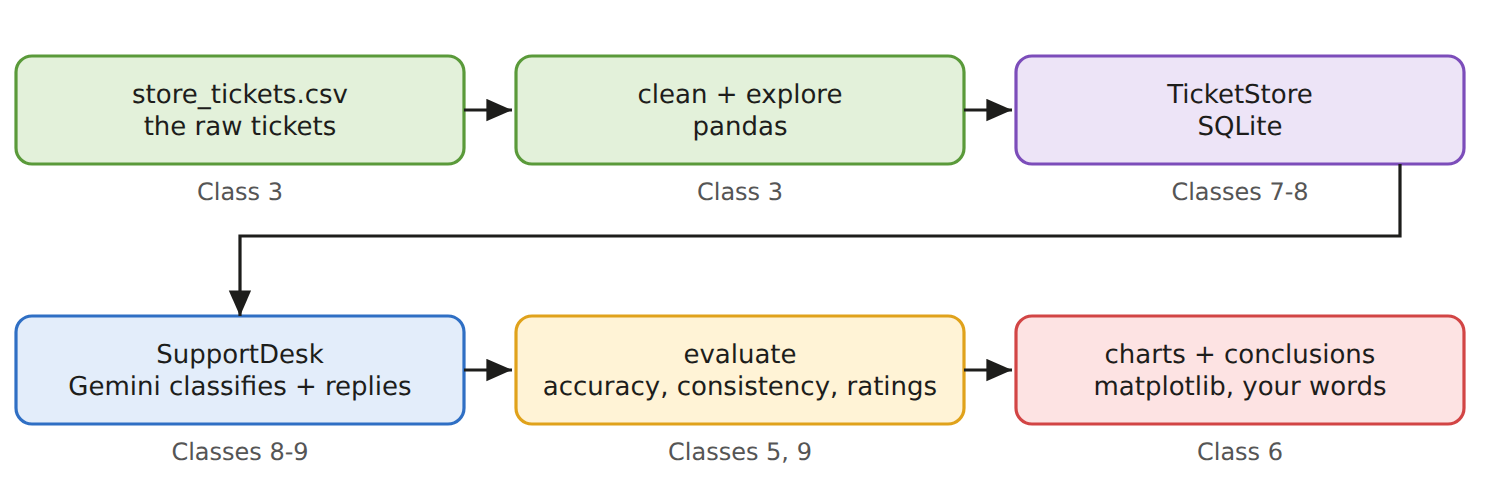

1. **Load and clean** a file of customer-support tickets from an online store, and explore it.
2. **Store** the tickets in a **SQLite** database.
3. **Triage with AI** — an **LLM (Google Gemini)** reads each ticket, predicts its **category**, and **drafts a reply**.
4. **Evaluate the AI** — how often is it right? Does it give the same answer twice? Are its replies any good?
5. **Show and explain** — charts of the tickets *and* of the AI's performance, and a short written conclusion.

---
## 2. The Data 📂

Use **`store_tickets.csv`**, in the `dataset` folder of the course repository: support tickets from an **online store that sells furniture, kitchen, garden, lighting and decor products**.

It is **not** the file from the classes: other columns, other categories, and problems of its own. You have learned every tool you need — choosing the right one is the job.

| Column | What it is |
|--------|-----------|
| `Ticket Number`, `Date` | which ticket, and the day it arrived |
| `Country`, `Channel`, `Priority`, `Status` | where it came from, and where it stands |
| `Order Number`, `Product Category`, `Order Value` | the order behind the ticket — empty when there is none |
| `Subject`, `Message` | the ticket's title, and the customer's own words — **what your AI reads** |
| `Category` | the **real category** — what your AI must predict: account help, delivery problem, payment issue, product question or return request |
| `Rating` | 1 to 5 — only for solved tickets |
| `Customer`, `Email`, `Phone`, `Internal Notes` | personal data, and an empty column: drop them |

> ⚠️ **The file is messy on purpose.** Before you clean anything, *look*: `.info()`, `.isnull().sum()`, `.unique()`. Some problems are like the ones in Class 3; at least one is new. Finding them is part of the job.

> 💡 **Not every empty cell is a mistake.** A question about a product has no order yet, so its `Order Number` is empty. Think before you drop rows.

> 💡 A few tickets contain **two requests in one message**. They are hard for an AI — and for a person. Look at them when you study the AI's mistakes.

---
## 3. Requirements ✅

| # | Your project must… | Where you practised it |
|---|-------------------|------------------------|
| 1 | Load, clean and explore the tickets with **pandas** | Class 3 — cleaning `support_tickets.csv` |
| 2 | Use **data structures**, and build **structured prompts** | Class 2 — dictionaries and messages; Class 9 — the grounded prompt |
| 3 | Organise the steps into **functions** | Class 4 — `clean_text()`, `find_answer()` |
| 4 | Use a **comprehension** (or `map` / `filter` / `zip`) for at least one transformation | Class 5 |
| 5 | Model the system with **classes** with encapsulated state: a `TicketStore` and a `SupportDesk` | Class 8 — `ChatMemory` and `FalconAssistant` |
| 6 | Put the reusable code in a **module notebook**, and `import` it | Class 9 — `falcon_tools`, `prompt_tools` |
| 7 | Call **Gemini** to classify the tickets and draft replies | Class 9 — the capstone, exercises D1–D2 |
| 8 | **Store** tickets, the AI's output, and your **feedback** in **SQLite**, and query it | Class 7 |
| 9 | **Evaluate the AI**: accuracy against the real label, a **consistency** check, and your ratings of its replies | Class 9 — exercises D2–D3 |
| 10 | **Chart** the ticket data *and* the AI's performance | Class 6 |
| 11 | Present your results **in writing**: text cells that explain each step and chart, like a report | Class 10 |

---
## 4. One Piece per Class 🧱

Do **not** leave it for the end. Each exercises notebook ends with this week's piece:

| After class | You add | It becomes Part |
|-------------|---------|-----------------|
| 1 | One ticket in variables, and a tidy summary printed with an `if` | — (warm-up) |
| 2 | Three tickets as dictionaries in a list, and the triage prompt as a message | — (warm-up) |
| 3 | Load, clean and explore `store_tickets.csv` | 1, 2 |
| 4 | Functions: `clean_tickets()`, `make_triage_prompt()`, `stand_in_classify()` | 2, 5 |
| 5 | A comprehension: the stand-in's answers for 20 tickets, and its accuracy | 5 |
| 6 | Charts of the ticket data | 3 |
| 7 | The tickets, and the stand-in's answers, in SQLite | 4 |
| 8 | The `TicketStore` and `SupportDesk` classes | 4, 5 |
| 9 | Everything in `support_tools.ipynb`; a Gemini desk; accuracy and consistency | 6, 8 |
| 10 | Feedback, the AI's charts, and the written report | 7, 9, 10 |

---
## 5. Technical Set-Up 🛠️

Everything runs in **Google Colab**. Your project is **two notebooks**, side by side in the Colab files panel, with `store_tickets.csv`:

```
support_tools.ipynb      MODULE: only definitions - functions and classes
ai_support_desk.ipynb    MAIN: imports support_tools, runs everything, charts, conclusions
```

**The top of your main notebook:**

```
!pip install -q import-ipynb google-genai

import import_ipynb
import support_tools as tools
```

**Your Gemini key** goes in the 🔑 **Secrets** panel, named `GEMINI_API_KEY` — **never** in the notebook (Class 9, Section 9):

```
from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
MODEL = "gemini-2.5-flash"                 # check the current free model at ai.google.dev
client = genai.Client(api_key=GEMINI_API_KEY)
```

### The free tier: a budget of requests

The free tier allows only a **few requests per minute**, and a limited number per day. So plan your requests like a budget:

| Step | Requests |
|------|----------|
| Classify **20** tickets, and draft a reply for each | 40 |
| Ask again about **10** of them (consistency) | 10 |
| **Total** | **50** |

> 💡 **Wait between requests.** The standard library's `time` module does it: `import time`, then `time.sleep(5)` inside your `ask_gemini()` function waits 5 seconds after each request. 50 requests take about 5 minutes — start the run, and read while it works.

> 💡 **Save each answer as soon as it arrives** — in your `TicketStore`, not only in a variable. If the run stops half-way, your work is still in the database.

---
## 6. The Parts, in Order 🧭

Each part leaves you with something that works. **Your output must show** tells you when a part is done.

> 🕐 **Short of time?** Parts **1, 2, 4, 5 and 6** are the core: clean data, stored, triaged by the stand-in and then by Gemini. A small, complete project beats a big unfinished one.

### Part 1 — Load and explore

Read `store_tickets.csv` into a DataFrame. Look at its size, its columns, its missing values, and the different values of `Category`.

**Your output must show:** 412 rows and 17 columns, the number of missing values in each column — including the tickets without a message — and the different ways `Category` is written.

### Part 2 — Clean, and a few statistics

Write `clean_tickets(tickets)` in your module: drop the duplicates, the empty and personal columns, and the tickets with no message, and make each category one spelling. Then compute a few statistics.

**Your output must show:** the cleaned shape (fewer rows than 412); exactly **5** categories, each written one way, with their counts; the average rating per category.

### Part 3 — Charts of the data

At least **two** charts about the tickets — for example tickets per category, and average rating per category.

**Your output must show:** charts with a title and labelled axes, which a reader understands without your help.

### Part 4 — The `TicketStore`

A class that owns the SQLite database — like `ChatMemory` in Class 8. It must be the **only** part of your program that writes SQL.

| Method | Does |
|--------|------|
| `load(tickets)` | writes the cleaned tickets with `.to_sql()`, and creates an empty `triage` table |
| `sample(n)` | returns the first `n` tickets as tuples: number, message, real category |
| `save_triage(...)` | saves the AI's category and reply for one ticket |
| `results()` | returns the `triage` table as a DataFrame, with `pd.read_sql_query` |

A `triage` table that works: `ticket_number`, `message`, `true_category`, `ai_category`, `ai_category_again`, `ai_reply`, `rating`.

**Your output must show:** the number of tickets in your sample, and one of them as a tuple.

### Part 5 — The stand-in desk: your baseline

A `SupportDesk` class — like `FalconAssistant` — with `classify()`, `draft_reply()` and `triage()`. First, `classify()` uses a **keyword stand-in model** (`stand_in_classify()`, like `find_answer()`), and `draft_reply()` returns a fixed sentence.

Triage your sample, and compute the stand-in's accuracy: the share of tickets where its category equals the real one.

**Your output must show:** the stand-in's accuracy — a number between 0 and 1. It will not be very good; that is the point.

### Part 6 — The Gemini desk

`GeminiDesk(SupportDesk)` inherits everything and **overrides only** `classify()` and `draft_reply()`, which now call Gemini — exactly the Class 9 capstone. Clean the model's category with `.lower().strip()`.

**Your output must show:** each ticket's number with Gemini's category, all from the 5 categories.

### Part 7 — Your feedback

Read **five** of the drafted replies. Rate each from 1 to 5, and save the ratings in the store.

**Your output must show:** the five tickets with their replies, and your ratings saved in the database.

### Part 8 — Evaluate the AI

| Measure | How |
|---------|-----|
| **Accuracy** | the share of tickets where `ai_category` equals `true_category` — compare it with the stand-in's |
| **Accuracy per category** | the same, grouped by the real category |
| **The mistakes** | print each wrong ticket: its message, the real category, the AI's category |
| **Consistency** | ask again about 10 tickets; the share of same answers |
| **Your ratings** | the average rating of the replies |

**Your output must show:** the two accuracies, accuracy per category, every mistake, the consistency, and the average rating.

### Part 9 — Charts of the AI's performance

At least **two** charts about the AI — for example stand-in against Gemini, and accuracy per category.

**Your output must show:** charts that answer *"how good is the AI, and where does it struggle?"*

### Part 10 — Results & conclusions

The last text cell of your report (see Section 10): 2–3 short paragraphs.

1. **The data** — one thing the tickets show.
2. **The AI** — how good it was, where it made mistakes, and **why** (read the mistakes!).
3. **Next** — one thing you would improve.

---
## 7. 🌟 Stretch Goals — a bonus

Extra challenges for those who want to go further. They are **not required**, but they work as a **bonus: +1 point on the final grade** if you do them. Try them only when Parts 1–10 work:

- Ask Gemini for the ticket's **priority** too, and evaluate it against `Priority`.
- Add **one example ticket per category** to the prompt, and measure whether the accuracy improves.
- Ask Gemini whether each drafted reply **promises something it shouldn't**, and count how often.
- Save your charts with `plt.savefig()`, to use them outside the notebook.

---
## 8. 💡 If You Get Stuck

| Problem | Look back at |
|---------|--------------|
| `Category` still has more than 5 values after `.str.lower()` | Print them with `.unique()` and look closely at the end of each one — then Class 4, `.strip()` (for a whole column: `.str.strip()`) |
| `No module named 'support_tools'` | Class 9, Section 4 — the module must be uploaded beside the main notebook |
| Your change to the module is ignored | Class 9 — *Runtime → Restart session*, then run from the top |
| `SecretNotFoundError`, `403`, `429` | Class 9, Section 10 — the error table |
| The same rows appear twice in the database | Class 7 — `CREATE TABLE IF NOT EXISTS`, then `DELETE FROM` |
| A class that owns a database | Class 8 capstone — `ChatMemory` |
| Replacing the model without touching the rest | Class 9 capstone — `GeminiAssistant(FalconAssistant)` |
| Accuracy and consistency | Class 9 exercises D2 and D3 |
| A chart with cut-off labels | Class 6 — `plt.tight_layout()` |

---
## 9. What to Hand In 📤

> 📤 **Submit on Moodle by Saturday, 21 November 2026.**

1. **`support_tools.ipynb`** — your module: functions and classes, no printing.
2. **`ai_support_desk.ipynb`** — your main notebook, with its outputs, written as a **report** (Section 10).

> ✅ **Before handing in:** *Runtime → Restart session*, then *Run all* **once**, with your key in 🔑 Secrets, to check the notebook runs from top to bottom. Then save it **with its outputs** — do not run the Gemini part again and again: every run spends your free requests.

---
## 10. Your Notebook Is the Report 📝

There is **no oral presentation**. Your main notebook **is** your report: someone who has never seen your project must understand it by reading it from top to bottom. The code shows *how*; the text cells say *what you found*.

| Where | A text cell that says |
|-------|-----------------------|
| At the top | a title, and in 2–3 sentences what your AI Support Desk does |
| Before each part | what this part does, and why |
| After each result or chart | what it shows, with the number — *"Gemini classified 18 of the 20 tickets correctly (0.90), against 0.55 for the keyword stand-in."* |
| At the end | **Results & conclusions** (Part 10) |

> 💡 Write for a manager, not for a programmer: short sentences, the numbers that matter, and no code in the text cells.

---
## 11. Grading 📊

**Two certificates:**
- 🎓 **Certificate of Attendance** — for **at least 75%** attendance (not graded).
- 🎓 **Certificate with Grade** — your final project, submitted on **Moodle** by **21 November 2026**, assessed with this rubric:

| Criterion | What we look for | Weight |
|-----------|------------------|:------:|
| **Data handling** | Loads, cleans and explores the tickets with pandas; sensible statistics | 15% |
| **Structure & logic** | Data structures, functions and a comprehension, used well | 15% |
| **Object-oriented design** | `TicketStore` and `SupportDesk` with encapsulated state — not loose variables | 15% |
| **Database** | Tickets, AI output and feedback stored in SQLite, and queried | 15% |
| **Modules** | Reusable code in a module notebook, imported into the main one | 10% |
| **Visualisation & analysis** | Clear charts of the data and of the AI's performance; the mistakes explained | 15% |
| **AI integration** | Working Gemini calls that classify tickets and draft replies, inside the desk | 10% |
| **Report & communication** | Readable code, and text cells that explain each step, each chart and the conclusions — a notebook that reads like a report | 5% |
| | **Total** | **100%** |
| 🌟 | **Bonus** — the stretch goals (Section 7) | **+1 point** |

> 💡 **Top marks** go to projects where the pieces **connect** into one system — not ten separate snippets.

---
## 12. Getting Started 🚀

1. Save a copy of this brief, and download `store_tickets.csv` from the `dataset` folder.
2. Create your two notebooks — they can be empty for now.
3. After each class, add **this week's piece** from the end of the exercises notebook.
4. Keep it **small but complete** — a working desk on 20 tickets beats an unfinished one on 300.

**Every skill you need is in this course. Now put them together, and build something real. 🐍🤖**

*Good luck! — Alexandra Oliveira and Catarina Santos · Porto Executive Academy × FALC-ON AI*